## Random Forest Setup

In [1]:
# --- Setup: load our toolbox ---
import numpy as np                     # numpy = calculator for lists of numbers
import pandas as pd                    # pandas = tool for working with tables of data
import matplotlib.pyplot as plt        # matplotlib = drawing charts
import seaborn as sns                  # seaborn = prettier charts
import warnings                        # lets us hide distracting warnings

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold  # data splitting + fair scoring
from sklearn.compose import ColumnTransformer      # different prep for different columns
from sklearn.pipeline import Pipeline              # chain prep + model into one assembly line
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # scale numbers; turn categories into 0/1 columns
from sklearn.impute import SimpleImputer           # fill in missing values
from sklearn.ensemble import RandomForestClassifier  # today's star: many trees voting together
from sklearn.metrics import f1_score, precision_score, recall_score  # scorecards

warnings.filterwarnings("ignore")           # keep output clean
sns.set_style("whitegrid")                  # light grid background for charts
plt.rcParams["figure.figsize"] = (11, 4.5)  # default chart size

print("✅ Libraries loaded — RandomForestClassifier ready")

✅ Libraries loaded — RandomForestClassifier ready


## Step 1 — Rebuild the dataset and preprocessor

In [2]:
# --- Same data, same split, same prep recipe as notebook 01 (so scores are comparable) ---
df = pd.read_csv("data/credit_card_fraud_2026.csv")     # load the customer table
y  = df["is_fraud"]                                # the answer to predict
X  = df.drop(columns=["transaction_id", "is_fraud"])  # the clues (drop ID and answer)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,  # identical split to L03 — fair comparison
)

# Which columns are numbers vs categories
numeric_features = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]
categorical_features = ["merchant_category", "card_type", "auth_method", "channel", "device_type", "is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]

# The data-prep recipe: fill gaps, scale numbers, encode categories
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),      # fill number gaps with median
                      ("scl", StandardScaler())]), numeric_features), # put all numbers on same scale
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),  # fill category gaps with most common
                      ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),  # categories -> 0/1 columns
                      categorical_features),
])

print("Dataset and preprocessor ready.")

Dataset and preprocessor ready.


## Step 2 — Train a Random Forest

In [3]:
# --- Random Forest: 200 trees voting together ---
rf_pipe = Pipeline([
    ("prep",  preprocessor),                 # step 1: prepare the data
    ("model", RandomForestClassifier(
        n_estimators=200,             # grow 200 different trees
        min_samples_leaf=5,           # mild regularisation: each leaf must hold at least 5 customers (stops memorising individuals)
        class_weight="balanced",      # ⚠ critical for imbalanced data — see explanation below
        n_jobs=-1,                    # use all CPU cores (just makes it faster)
        random_state=42,              # repeatable results
    )),
])

rf_pipe.fit(X_train, y_train)   # train all 200 trees on the training customers

# Evaluate at default threshold 0.5
y_proba_rf = rf_pipe.predict_proba(X_test)[:, 1]   # each customer's fraud probability = share of trees voting "fraud"
y_pred_rf_05 = (y_proba_rf >= 0.5).astype(int)     # flag if more than half the trees say fraud

# And at the L03 capacity-based threshold of 0.05
y_pred_rf_005 = (y_proba_rf >= 0.05).astype(int)    # lower bar = flag more customers = higher recall

# Scorecard at both thresholds
print("=== Random Forest, default 0.5 threshold ===")
print(f"F1:        {f1_score(y_test, y_pred_rf_05):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_05, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_05):.3f}")
print(f"Flagged:   {int(y_pred_rf_05.sum())}")
print()
print("=== Random Forest, capacity-based 0.05 threshold (matching 04) ===")
print(f"F1:        {f1_score(y_test, y_pred_rf_005):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_005, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_005):.3f}")
print(f"Flagged:   {int(y_pred_rf_005.sum())}")
print()
# NOTE: 0.28 is a snapshot of the L03 baseline from when this lesson was written.
# Your exact number may differ slightly if the data or split ever changes — the comparison still holds.
print("L03 baseline F1 at threshold 0.05: around 0.067 (snapshot — your exact number may differ slightly)")

=== Random Forest, default 0.5 threshold ===
F1:        0.268
Precision: 0.288
Recall:    0.250
Flagged:   59

=== Random Forest, capacity-based 0.05 threshold (matching 04) ===
F1:        0.067
Precision: 0.035
Recall:    0.985
Flagged:   1919

L03 baseline F1 at threshold 0.05: around 0.067 (snapshot — your exact number may differ slightly)


## Step 3 - check 10 features from RF 

Top 10 features by RF importance:
                      feature  importance
          merchant_risk_score    0.118426
              cvv_retry_count    0.103616
               velocity_score    0.086830
    ip_country_mismatch_False    0.045399
auth_method_No Authentication    0.045322
         hours_since_last_txn    0.040890
     ip_country_mismatch_True    0.038302
             time_of_day_hour    0.034253
          account_balance_usd    0.033742
                   amount_usd    0.033674


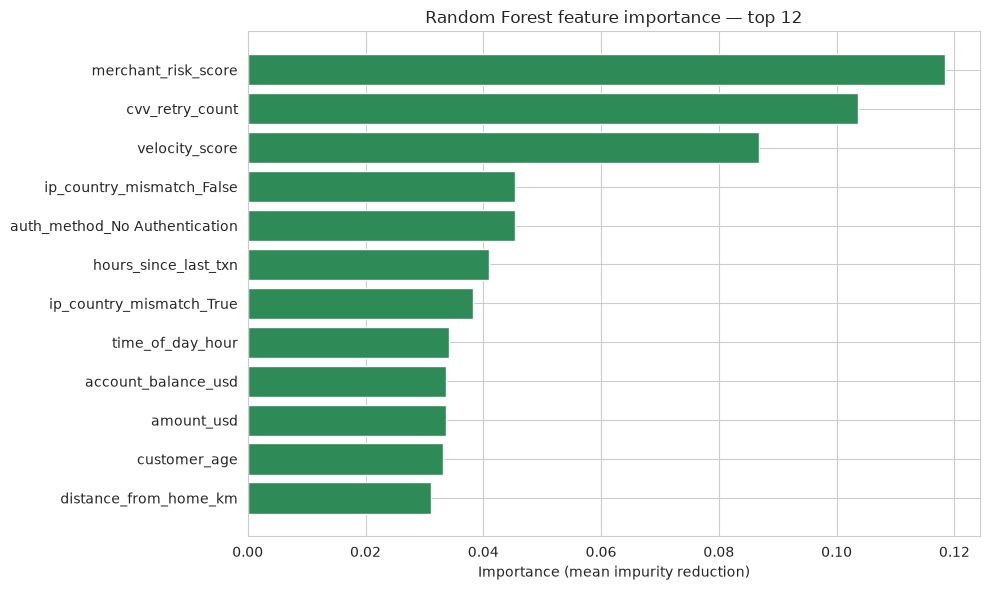

In [4]:
# --- Which clues does the forest rely on most? (Feature importance) ---
# Feature importance — averaged across all 200 trees
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()  # names of columns after prep
importances   = rf_pipe.named_steps["model"].feature_importances_    # how much each column helped the trees split well

# Put names and scores side by side in a table, biggest first
imp_df = pd.DataFrame({
    "feature":    [name.split("__")[-1] for name in feature_names],  # strip the "num__"/"cat__" prefixes
    "importance": importances,
}).sort_values("importance", ascending=False)

print("Top 10 features by RF importance:")
print(imp_df.head(10).to_string(index=False))

# Plot top features as a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))
top = imp_df.head(12).iloc[::-1]                # take top 12, reverse so biggest bar sits on top
ax.barh(top["feature"], top["importance"], color="seagreen", edgecolor="white")
ax.set_xlabel("Importance (mean impurity reduction)")
ax.set_title("Random Forest feature importance — top 12")
plt.tight_layout()
plt.show()

## Step 4 - Compare Logistics Regress, RF (without or with class_weight='balanced')

In [5]:
# --- What happens if we DON'T tell the model the classes are imbalanced? ---
# Train RF without class_weight='balanced' to get a real CV F1 for comparison
rf_no_balance = Pipeline([
    ("prep",  preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,   # same forest, but NO class_weight
        n_jobs=-1, random_state=42,
    )),
])
# Score it the same fair way (5-fold cross-validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # 5 different train/check splits, churn % kept equal in each

cv_f1_rf_no_balance = cross_val_score(
    rf_no_balance, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1
).mean()

# L03 LR baseline (no class_weight) — from L03 notebook, hardcoded here
lr_baseline_f1 = 0.05

# Three bars: baseline, RF unbalanced, RF balanced
labels = [
    "Logistic Regression\n(no class_weight='balanced')",
    "Random Forest\n(no class_weight='balanced')",
    "Random Forest\n(class_weight='balanced')",
]
values = [lr_baseline_f1, cv_f1_rf_no_balance, cv_f1_rf.mean()]
colors = ["#c0392b", "#e07b39", "seagreen"]    # red / orange / green

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(labels, values, color=colors, edgecolor="white", height=0.45)

# Write each score at the end of its bar
for bar, val in zip(bars, values):
    ax.text(
        val + 0.003, bar.get_y() + bar.get_height() / 2,
        f"{val:.3f}", va="center", fontsize=10, fontweight="bold",
    )

ax.set_xlabel("CV F1 (threshold 0.5)")
ax.set_title("Effect of class_weight='balanced' — all three models compared")
ax.set_xlim(0, max(values) * 1.25)   # leave room for the score labels
ax.invert_yaxis()                    # show baseline at the top
plt.tight_layout()
plt.show()

print(f"LR baseline (no rebalancing):          CV F1 = {lr_baseline_f1:.3f}  [from L03]")
print(f"RF without class_weight='balanced':    CV F1 = {cv_f1_rf_no_balance:.3f}")
print(f"RF with    class_weight='balanced':    CV F1 = {cv_f1_rf.mean():.3f}")

NameError: name 'cv_f1_rf' is not defined

## ✅ Section Summary

| Model | CV F1 (threshold 0.5) | Comment |
|---|---|---|
| **L03 LogisticRegression** (no rebalancing) | ~0.05 | Probabilities too concentrated near 0 |
| **Random Forest** without `class_weight='balanced'` | ~0.00 | Same problem — collapses to majority class |
| **Random Forest with `class_weight='balanced'`** | ~0.324 | ← **the comparable Core baseline** |
